# Proyek Analisis Data: Brazilian E-Commerce Public Dataset by Olist
- **Nama:** Najwa Agustin
- **Email:** nazwagstin68@gmail.com
- **ID Dicoding:** nzwagstin

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1:** Sales Performance: Bagaimana perkembangan jumlah pesanan, total pendapatan, dan Average Order Value (AOV) setiap bulan selama Januari 2017 hingga Agustus 2018, serta bulan apa yang menunjukkan performa tertinggi dan terendah, sebagai dasar penentuan periode promosi dan perencanaan penjualan?

**Pertanyaan 2:** Customer RFM: Bagaimana karakteristik pelanggan berdasarkan Recency, Frequency, Monetary, dan distribusi segmen RFM dari riwayat transaksi selama periode 1 Januari 2017 hingga 31 Agustus 2018, dengan tanggal analisis 1 September 2018, sebagai dasar penentuan strategi retensi pelanggan dan program pembelian ulang?

**Pertanyaan 3:**Delivery Performance: Bagaimana persentase pesanan yang terkirim tepat waktu dan terlambat, serta rata-rata durasi pengiriman selama Januari 2017 hingga Agustus 2018, sebagai dasar evaluasi kinerja logistik dan penentuan prioritas perbaikan pengiriman?

[link text](https://)## Import Semua Packages/Library yang Digunakan

In [1]:
# Data Analysis
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Processing
import os
import warnings
from pathlib import Path
from datetime import datetime

# Display Settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Visualization Settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Ignore Warnings
warnings.filterwarnings('ignore')

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


## Data Wrangling

### Gathering Data

#### Load df Brazilian E-Commerce Public dataset

In [2]:

# Memuat seluruh dataset
customers = pd.read_csv('/content/customers_dataset.csv')
geolocation = pd.read_csv('/content/geolocation_dataset.csv')
order_items = pd.read_csv('/content/order_items_dataset.csv')
order_payments = pd.read_csv('/content/order_payments_dataset.csv')
order_reviews = pd.read_csv('/content/order_reviews_dataset.csv')
orders = pd.read_csv('/content/orders_dataset.csv')
products = pd.read_csv('/content/products_dataset.csv')
sellers = pd.read_csv('/content/sellers_dataset.csv')
category_translation = pd.read_csv('/content/product_category_name_translation.csv')

print("Seluruh dataset berhasil dimuat!")


Seluruh dataset berhasil dimuat!


In [3]:
# Menampilkan jumlah baris dan kolom setiap dataset
datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Order Payments": order_payments,
    "Order Reviews": order_reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (99441, 5)
Geolocation: (1000163, 5)
Order Items: (112650, 7)
Order Payments: (103886, 5)
Order Reviews: (99224, 7)
Orders: (99441, 8)
Products: (32951, 9)
Sellers: (3095, 4)
Category Translation: (71, 2)


**Insight:**
- Dataset Brazilian E-Commerce Public Dataset by Olist terdiri dari 9 file dengan struktur dan jumlah data yang berbeda-beda.
- Dataset Geolocation memiliki jumlah data terbesar, yaitu 1.000.163 baris, sedangkan Category Translation memiliki jumlah data terkecil, yaitu 71 baris.
- Dataset Orders dan Customers masing-masing memiliki 99.441 baris, yang menunjukkan jumlah record pada kedua tabel tersebut sama, tetapi belum memastikan seluruh relasi datanya sesuai.
- Dataset memiliki informasi yang saling melengkapi, mulai dari data pelanggan, pesanan, produk, pembayaran, penjual, hingga ulasan dan lokasi.
- Keberagaman struktur dataset memungkinkan analisis performa penjualan, perilaku pelanggan menggunakan RFM, serta performa pengiriman.

### Assessing Data

#### Identifying Brazilian E-Commerce Public dataset problem

In [4]:
# Identifikasi permasalahan kualitas data
for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print(f"Jumlah Baris       : {df.shape[0]}")
    print(f"Jumlah Kolom       : {df.shape[1]}")
    print(f"Missing Values     : {df.isnull().sum().sum()}")
    print(f"Duplicate Data     : {df.duplicated().sum()}")
    print(f"Jumlah Tipe Data   : {df.dtypes.nunique()}")


===== Customers =====
Jumlah Baris       : 99441
Jumlah Kolom       : 5
Missing Values     : 0
Duplicate Data     : 0
Jumlah Tipe Data   : 2

===== Geolocation =====
Jumlah Baris       : 1000163
Jumlah Kolom       : 5
Missing Values     : 0
Duplicate Data     : 261831
Jumlah Tipe Data   : 3

===== Order Items =====
Jumlah Baris       : 112650
Jumlah Kolom       : 7
Missing Values     : 0
Duplicate Data     : 0
Jumlah Tipe Data   : 3

===== Order Payments =====
Jumlah Baris       : 103886
Jumlah Kolom       : 5
Missing Values     : 0
Duplicate Data     : 0
Jumlah Tipe Data   : 3

===== Order Reviews =====
Jumlah Baris       : 99224
Jumlah Kolom       : 7
Missing Values     : 145903
Duplicate Data     : 0
Jumlah Tipe Data   : 2

===== Orders =====
Jumlah Baris       : 99441
Jumlah Kolom       : 8
Missing Values     : 4908
Duplicate Data     : 0
Jumlah Tipe Data   : 1

===== Products =====
Jumlah Baris       : 32951
Jumlah Kolom       : 9
Missing Values     : 2448
Duplicate Data     : 0


In [5]:
# Memeriksa missing values setiap kolom
for name, df in datasets.items():
    missing = df.isnull().sum()

    if missing.sum() > 0:
        print(f"\n===== {name} =====")
        print(missing[missing > 0])


===== Order Reviews =====
review_comment_title      87656
review_comment_message    58247
dtype: int64

===== Orders =====
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

===== Products =====
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [6]:
# Memeriksa status pesanan yang memiliki tanggal kosong
missing_orders = orders[orders[
    ['order_approved_at',
     'order_delivered_carrier_date',
     'order_delivered_customer_date']
].isnull().any(axis=1)]

print("Jumlah pesanan dengan tanggal kosong:",
      len(missing_orders))

print("\nDistribusi status pesanan:")
print(missing_orders['order_status'].value_counts())

print("\nDetail missing values berdasarkan status:")
print(
    missing_orders.groupby('order_status')[
        ['order_approved_at',
         'order_delivered_carrier_date',
         'order_delivered_customer_date']
    ].apply(lambda x: x.isnull().sum())
)

Jumlah pesanan dengan tanggal kosong: 2980

Distribusi status pesanan:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered        23
created           5
approved          2
Name: count, dtype: int64

Detail missing values berdasarkan status:
              order_approved_at  order_delivered_carrier_date  \
order_status                                                    
approved                      0                             2   
canceled                    141                           550   
created                       5                             5   
delivered                    14                             2   
invoiced                      0                           314   
processing                    0                           301   
shipped                       0                             0   
unavailable                   0                           609   

              order_delivered_custom

In [7]:
# Memeriksa pesanan delivered yang memiliki tanggal kosong
delivered_missing = orders[
    (orders['order_status'] == 'delivered') &
    (
        orders['order_approved_at'].isnull() |
        orders['order_delivered_carrier_date'].isnull() |
        orders['order_delivered_customer_date'].isnull()
    )
]

display(delivered_missing)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00


In [8]:
# Memeriksa validitas urutan tanggal pesanan
orders_check = orders.copy()

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_check[col] = pd.to_datetime(
        orders_check[col], errors='coerce'
    )

# Memeriksa urutan tanggal yang tidak sesuai
invalid_dates = {
    'Approval sebelum pembelian':
        orders_check['order_approved_at'] <
        orders_check['order_purchase_timestamp'],

    'Pengiriman ke kurir sebelum pembelian':
        orders_check['order_delivered_carrier_date'] <
        orders_check['order_purchase_timestamp'],

    'Penerimaan sebelum pengiriman ke kurir':
        orders_check['order_delivered_customer_date'] <
        orders_check['order_delivered_carrier_date'],

    'Penerimaan sebelum pembelian':
        orders_check['order_delivered_customer_date'] <
        orders_check['order_purchase_timestamp']
}

for label, condition in invalid_dates.items():
    print(f"{label}: {condition.sum()} data")

Approval sebelum pembelian: 0 data
Pengiriman ke kurir sebelum pembelian: 166 data
Penerimaan sebelum pengiriman ke kurir: 23 data
Penerimaan sebelum pembelian: 0 data


In [9]:
# Menggabungkan kondisi tanggal yang tidak sesuai
invalid_mask = (
    invalid_dates['Pengiriman ke kurir sebelum pembelian'] |
    invalid_dates['Penerimaan sebelum pengiriman ke kurir']
)

# Menampilkan data yang bermasalah
invalid_orders = orders_check.loc[
    invalid_mask,
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date'
    ]
]

print("Jumlah pesanan dengan ketidaksesuaian tanggal:",
      len(invalid_orders))

display(invalid_orders.head(20))

Jumlah pesanan dengan ketidaksesuaian tanggal: 189


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00,2018-08-24 14:58:37
1111,ad133696906f6a78826daa0911b7daec,delivered,2018-06-15 15:41:22,2018-06-15 16:19:23,2018-06-15 14:52:00,2018-06-22 18:09:37
1329,74e033208dc13a7b8127eb8e73d09b76,delivered,2018-05-02 10:48:44,2018-05-02 11:13:45,2018-05-02 09:49:00,2018-05-07 23:06:36
1372,a6b58794fd2ba533359a76c08df576e3,delivered,2018-05-14 15:18:23,2018-05-14 15:33:35,2018-05-14 13:46:00,2018-05-19 19:33:32
1864,5792e0b1c8c8a2bf53af468c9a422c88,delivered,2018-07-26 13:25:14,2018-07-26 13:35:14,2018-07-26 12:42:00,2018-07-30 14:45:02
2760,c3eb293fd154223498b6551a728203e8,delivered,2018-07-19 14:06:04,2018-07-19 14:22:51,2018-07-19 13:49:00,2018-07-24 19:35:36
3473,b0c2a7d04b165525254254a728c50a4e,delivered,2018-06-07 13:28:30,2018-06-07 13:57:22,2018-06-07 13:22:00,2018-06-21 17:36:43
3661,2033a4586b5bec3229ebc1675a8ae092,delivered,2018-06-12 10:10:25,2018-06-12 10:39:59,2018-06-12 10:09:00,2018-06-19 14:08:27
4114,08adcddad19d3acf37d1fa01cb9ded1e,delivered,2018-06-27 11:16:44,2018-06-27 11:30:56,2018-06-27 10:57:00,2018-06-29 17:39:53
4159,dee6298ce7d1fb2645141ef9972157aa,shipped,2018-04-30 14:06:12,2018-04-30 14:15:24,2018-04-30 12:59:00,NaT


In [10]:
# Memisahkan dua jenis ketidaksesuaian tanggal
carrier_before_purchase = (
    orders_check['order_delivered_carrier_date'] <
    orders_check['order_purchase_timestamp']
)

customer_before_carrier = (
    orders_check['order_delivered_customer_date'] <
    orders_check['order_delivered_carrier_date']
)

# Menghitung jumlah setiap kondisi
print("Kurir sebelum pembelian:",
      carrier_before_purchase.sum())

print("Penerimaan sebelum penyerahan ke kurir:",
      customer_before_carrier.sum())

print("Mengalami kedua kondisi:",
      (carrier_before_purchase & customer_before_carrier).sum())

invalid_timestamp_mask = (
    carrier_before_purchase | customer_before_carrier
)
print("Total pesanan unik dengan timestamp tidak konsisten:",
      invalid_timestamp_mask.sum())

print("\\nStatus pesanan pada data bermasalah:")
display(orders_check.loc[
    invalid_timestamp_mask, 'order_status'
].value_counts())

print("\\nKeputusan cleaning:")
print("- 189 pesanan tetap disimpan pada dataset Orders untuk menjaga data sumber.")
print("- 188 di antaranya berstatus delivered dan 1 berstatus shipped.")
print("- Pesanan delivered yang timestamp-nya tidak konsisten dikeluarkan")
print("  dari analisis performa pengiriman, bukan dihapus dari seluruh dataset.")

Kurir sebelum pembelian: 166
Penerimaan sebelum penyerahan ke kurir: 23
Mengalami kedua kondisi: 0
Total pesanan unik dengan timestamp tidak konsisten: 189
\nStatus pesanan pada data bermasalah:


,count
order_status,
delivered,188
shipped,1


\nKeputusan cleaning:
- 189 pesanan tetap disimpan pada dataset Orders untuk menjaga data sumber.
- 188 di antaranya berstatus delivered dan 1 berstatus shipped.
- Pesanan delivered yang timestamp-nya tidak konsisten dikeluarkan
  dari analisis performa pengiriman, bukan dihapus dari seluruh dataset.


In [11]:
# Memeriksa duplikasi berdasarkan kolom identitas
duplicate_checks = {
    'Customers': (customers, 'customer_id'),
    'Orders': (orders, 'order_id'),
    'Products': (products, 'product_id'),
    'Sellers': (sellers, 'seller_id'),
    'Order Items': (order_items, ['order_id', 'order_item_id']),
    'Order Payments': (order_payments, ['order_id', 'payment_sequential']),
    'Order Reviews': (order_reviews, 'review_id')
}

for name, (df, key) in duplicate_checks.items():
    print(f"{name}: {df.duplicated(subset=key).sum()} duplikasi")

Customers: 0 duplikasi
Orders: 0 duplikasi
Products: 0 duplikasi
Sellers: 0 duplikasi
Order Items: 0 duplikasi
Order Payments: 0 duplikasi
Order Reviews: 814 duplikasi


In [12]:
# Mengambil data dengan review_id yang duplikat
duplicate_reviews = order_reviews[
    order_reviews.duplicated(
        subset=['review_id'],
        keep=False
    )
].sort_values('review_id')

print("Jumlah baris yang terindikasi duplikat:",
      len(duplicate_reviews))

display(duplicate_reviews.head(20))

Jumlah baris yang terindikasi duplikat: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [13]:
# Memeriksa variasi order_id dan isi ulasan pada setiap review_id
review_detail = (
    order_reviews.groupby('review_id')
    .agg(
        jumlah_baris=('order_id', 'size'),
        jumlah_order=('order_id', 'nunique'),
        jumlah_score=('review_score', 'nunique'),
        jumlah_komentar=('review_comment_message', 'nunique'),
        jumlah_tanggal=('review_creation_date', 'nunique')
    )
)

# Mengambil review_id yang muncul lebih dari sekali
review_detail = review_detail[
    review_detail['jumlah_baris'] > 1
]

display(review_detail.describe())

,jumlah_baris,jumlah_order,jumlah_score,jumlah_komentar,jumlah_tanggal
count,789.00,789.00,789.00,789.00,789.00
mean,2.03,2.03,1.00,0.38,1.00
std,0.18,0.18,0.00,0.49,0.00
min,2.00,2.00,1.00,0.00,1.00
25%,2.00,2.00,1.00,0.00,1.00
50%,2.00,2.00,1.00,0.00,1.00
75%,2.00,2.00,1.00,1.00,1.00
max,3.00,3.00,1.00,1.00,1.00


In [14]:
print("Review ID dengan beberapa order:",
      (review_detail['jumlah_order'] > 1).sum())

print("Review ID dengan beberapa score:",
      (review_detail['jumlah_score'] > 1).sum())

print("Review ID dengan beberapa komentar:",
      (review_detail['jumlah_komentar'] > 1).sum())

print("Review ID dengan beberapa tanggal:",
      (review_detail['jumlah_tanggal'] > 1).sum())

Review ID dengan beberapa order: 789
Review ID dengan beberapa score: 0
Review ID dengan beberapa komentar: 0
Review ID dengan beberapa tanggal: 0


In [15]:
# Memeriksa tipe data seluruh dataset
for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print(df.dtypes)


===== Customers =====
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

===== Geolocation =====
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

===== Order Items =====
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

===== Order Payments =====
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

===== Order Reviews =====
review_id                  object
order_id                   object
r

In [16]:
date_columns = {
    'Order Items': ['shipping_limit_date'],
    'Order Reviews': [
        'review_creation_date',
        'review_answer_timestamp'
    ],
    'Orders': [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
}

for name, columns in date_columns.items():
    df = datasets[name].copy()

    print(f"\n===== {name} =====")

    for col in columns:
        converted = pd.to_datetime(df[col], errors='coerce')

        failed = df[col].notna().sum() - converted.notna().sum()

        print(f"{col}")
        print(f"  Gagal dibaca sebagai tanggal: {failed}")


===== Order Items =====
shipping_limit_date
  Gagal dibaca sebagai tanggal: 0

===== Order Reviews =====
review_creation_date
  Gagal dibaca sebagai tanggal: 0
review_answer_timestamp
  Gagal dibaca sebagai tanggal: 0

===== Orders =====
order_purchase_timestamp
  Gagal dibaca sebagai tanggal: 0
order_approved_at
  Gagal dibaca sebagai tanggal: 0
order_delivered_carrier_date
  Gagal dibaca sebagai tanggal: 0
order_delivered_customer_date
  Gagal dibaca sebagai tanggal: 0
order_estimated_delivery_date
  Gagal dibaca sebagai tanggal: 0


In [17]:
# Membuat salinan seluruh dataset
cleaned_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

print("Jumlah dataset:", len(cleaned_datasets))

for name, df in cleaned_datasets.items():
    print(f"{name}: {df.shape}")

Jumlah dataset: 9
Customers: (99441, 5)
Geolocation: (1000163, 5)
Order Items: (112650, 7)
Order Payments: (103886, 5)
Order Reviews: (99224, 7)
Orders: (99441, 8)
Products: (32951, 9)
Sellers: (3095, 4)
Category Translation: (71, 2)


**Steps to Take:**
- Memeriksa jumlah baris, kolom, missing values, dan duplikasi pada seluruh dataset.
- Mengidentifikasi missing values pada setiap kolom untuk mengetahui kelengkapan data.
- Memeriksa duplikasi data secara keseluruhan dan berdasarkan kolom identitas utama (primary key).
- Memeriksa konsistensi timestamp pada dataset Orders untuk mengidentifikasi urutan waktu yang tidak sesuai.
- Memeriksa tipe data setiap kolom untuk memastikan kesesuaiannya dengan jenis informasi yang disimpan.
- Menguji keterbacaan format tanggal menggunakan pd.to_datetime() tanpa mengubah dataset asli.

**Insight:**
- Dataset Geolocation memiliki 261.831 baris duplikat identik. Duplikasi ditangani dengan `drop_duplicates()` sebelum pemeriksaan koordinat.
- Dataset Order Reviews memiliki missing values pada kolom komentar. Nilai tersebut perlu ditinjau karena pelanggan dapat memberikan rating tanpa menulis komentar.
- Dataset Orders memiliki missing values pada timestamp: 160 pada `order_approved_at`, 1.783 pada `order_delivered_carrier_date`, dan 2.965 pada `order_delivered_customer_date`. Missing values tidak hanya ditemukan pada pesanan yang belum selesai; terdapat juga pesanan berstatus `delivered` dengan 14 timestamp approval, 2 timestamp penyerahan ke kurir, dan 8 timestamp penerimaan yang kosong.
- Ditemukan 189 pesanan dengan urutan timestamp tidak konsisten. Temuan ini perlu ditangani khusus pada analisis pengiriman.
- Dataset Products memiliki missing values pada atribut kategori dan atribut deskriptif/dimensi produk.
- Beberapa kolom tanggal masih bertipe object, tetapi seluruh nilai non-null berhasil dikonversi menjadi datetime saat pengujian.

### Cleaning Data

#### Penanganan Missing Values, Duplikasi, dan Nilai Tidak Valid

Pada tahap cleaning, penanganan dilakukan sesuai jenis masalah. Nilai yang tidak memiliki dasar pengisian tidak dipaksakan untuk diimputasi. Data dengan timestamp tidak konsisten dipertahankan pada dataset Orders untuk audit, tetapi dikeluarkan dari analisis durasi pengiriman agar tidak menghasilkan metrik yang menyesatkan.

In [18]:
# Kolom tanggal yang akan dikonversi
date_columns = {
    'Order Items': ['shipping_limit_date'],

    'Order Reviews': [
        'review_creation_date',
        'review_answer_timestamp'
    ],

    'Orders': [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
}

# Konversi tipe data tanggal
for name, columns in date_columns.items():
    for col in columns:
        cleaned_datasets[name][col] = pd.to_datetime(
            cleaned_datasets[name][col],
            errors='coerce'
        )

print("Konversi tipe data tanggal selesai.")

Konversi tipe data tanggal selesai.


In [19]:
for name, columns in date_columns.items():
    print(f"\n===== {name} =====")

    for col in columns:
        print(f"{col}: {cleaned_datasets[name][col].dtype}")


===== Order Items =====
shipping_limit_date: datetime64[ns]

===== Order Reviews =====
review_creation_date: datetime64[ns]
review_answer_timestamp: datetime64[ns]

===== Orders =====
order_purchase_timestamp: datetime64[ns]
order_approved_at: datetime64[ns]
order_delivered_carrier_date: datetime64[ns]
order_delivered_customer_date: datetime64[ns]
order_estimated_delivery_date: datetime64[ns]


#### Fixing Missing Values  Dataset Orders

In [20]:
orders_clean = cleaned_datasets['Orders']

print("Missing Values pada Dataset Orders:")
display(
    orders_clean.isnull().sum()[orders_clean.isnull().sum() > 0]
)

# Memeriksa missing values tanggal berdasarkan status pesanan
order_date_cols = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

missing_by_status = (
    orders_clean.groupby('order_status')[order_date_cols]
    .apply(lambda df: df.isna().sum())
)

print("\\nMissing values timestamp berdasarkan status pesanan:")
display(missing_by_status)

print("\\nPesanan delivered yang memiliki timestamp kosong:")
delivered_missing_dates = orders_clean[
    (orders_clean['order_status'] == 'delivered') &
    (orders_clean[order_date_cols].isna().any(axis=1))
]
display(delivered_missing_dates[
    ['order_id', *order_date_cols]
])

Missing Values pada Dataset Orders:


,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965


\nMissing values timestamp berdasarkan status pesanan:


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


\nPesanan delivered yang memiliki timestamp kosong:


,order_id,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT
5323,e04abd8149ef81b95221e88f6ed9ab6a,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33
16567,8a9adc69528e1001fc68dd0aaebbb54a,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06
19031,7013bcfc1c97fe719a7b5e05e61c12db,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT
22663,5cf925b116421afa85ee25e99b4c34fb,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47
23156,12a95a3c06dbaec84bcfb0e2da5d228a,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19
26800,c1d4211b3dae76144deccd6c74144a88,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01
38290,d69e5d356402adc8cf17e08b5033acfb,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58
39334,d77031d6a3c8a52f019764e68f211c69,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23


In [21]:
print("Distribusi Status Pesanan:")
display(orders_clean['order_status'].value_counts())

Distribusi Status Pesanan:


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


#### Fixing Missing Values — Dataset Products

In [22]:
products_clean = cleaned_datasets['Products']

print("Missing Values pada Dataset Products:")
display(
    products_clean.isnull().sum()[
        products_clean.isnull().sum() > 0
    ]
)

Missing Values pada Dataset Products:


,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [23]:
missing_products = products_clean[
    products_clean.isnull().any(axis=1)
]

print("Jumlah produk dengan missing values:", len(missing_products))

display(missing_products.head(10))

Jumlah produk dengan missing values: 611


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.00,17.00,14.00,12.00
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.00,16.00,7.00,20.00
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.00,20.00,20.00,20.00
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,"18,500.00",41.00,30.00,41.00
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.00,35.00,7.00,12.00
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,"2,200.00",16.00,2.00,11.00
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.00,16.00,7.00,11.00
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.00,18.00,8.00,14.00
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.00,22.00,14.00,14.00
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,"1,400.00",25.00,25.00,25.00


In [24]:
# Mengisi kategori produk yang kosong dengan label Unknown
products_clean['product_category_name'] = (
    products_clean['product_category_name'].fillna('Unknown')
)

# Mempertahankan missing pada atribut deskriptif/dimensi karena
# tidak ada informasi yang cukup untuk menentukan nilai penggantinya.
# Nilai 0 pada berat produk diperlakukan sebagai nilai tidak valid.
products_clean['product_weight_g'] = products_clean['product_weight_g'].replace(0, np.nan)

# Memperbarui dataset hasil cleaning
cleaned_datasets['Products'] = products_clean

print("Missing Values kategori setelah penanganan:",
      products_clean['product_category_name'].isnull().sum())
print("\\nMissing values Products per kolom:")
display(products_clean.isnull().sum()[products_clean.isnull().sum() > 0])

Missing Values kategori setelah penanganan: 0
\nMissing values Products per kolom:


,0
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,6
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [25]:
# Menangani nilai tidak valid pada dataset Order Payments
payments_clean = cleaned_datasets['Order Payments'].copy()

print("Nilai payment_installments = 0:",
      (payments_clean['payment_installments'] == 0).sum())
print("Nilai payment_value = 0:",
      (payments_clean['payment_value'] == 0).sum())

# Nol pada installments tidak valid sebagai jumlah cicilan.
payments_clean['payment_installments'] = (
    payments_clean['payment_installments'].replace(0, np.nan)
)

# Nilai pembayaran nol ditandai sebagai missing agar tidak dianggap
# sebagai transaksi dengan nilai pembayaran yang terverifikasi.
payments_clean['payment_value'] = (
    payments_clean['payment_value'].replace(0, np.nan)
)

cleaned_datasets['Order Payments'] = payments_clean

# Ringkasan missing values Products setelah penanganan
products_clean = cleaned_datasets['Products']
print("\\nMissing Values Products setelah penanganan:")
display(products_clean.isnull().sum()[products_clean.isnull().sum() > 0])

# Ringkasan nilai tidak valid yang sudah ditandai
print("\\nMissing Values Order Payments setelah penanganan:")
display(payments_clean.isnull().sum()[payments_clean.isnull().sum() > 0])

Nilai payment_installments = 0: 2
Nilai payment_value = 0: 9
\nMissing Values Products setelah penanganan:


,0
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,6
product_length_cm,2
product_height_cm,2
product_width_cm,2


\nMissing Values Order Payments setelah penanganan:


,0
payment_installments,2
payment_value,9


#### Fixing Missing Values — Dataset Order Reviews

In [26]:
reviews_clean = cleaned_datasets['Order Reviews']

print("Missing Values pada Order Reviews:")
display(
    reviews_clean.isnull().sum()[
        reviews_clean.isnull().sum() > 0
    ]
)

Missing Values pada Order Reviews:


,0
review_comment_title,87656
review_comment_message,58247


In [27]:
print("Distribusi Review Score:")
display(reviews_clean['review_score'].value_counts().sort_index())

Distribusi Review Score:


,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [28]:
geolocation_clean = cleaned_datasets['Geolocation']

# Memeriksa jumlah duplikasi seluruh kolom
print("Duplikasi seluruh kolom:",
      geolocation_clean.duplicated().sum())

# Memeriksa jumlah kode pos unik
print("Jumlah kode pos unik:",
      geolocation_clean['geolocation_zip_code_prefix'].nunique())

# Memeriksa jumlah koordinat unik
print("Jumlah kombinasi koordinat unik:",
      geolocation_clean[
          ['geolocation_lat', 'geolocation_lng']
      ].drop_duplicates().shape[0])

# Melihat contoh baris yang terduplikasi
duplicate_geo = geolocation_clean[
    geolocation_clean.duplicated(keep=False)
].sort_values('geolocation_zip_code_prefix')

display(duplicate_geo.head(10))

Duplikasi seluruh kolom: 261831
Jumlah kode pos unik: 19015
Jumlah kombinasi koordinat unik: 718463


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
851,1001,-23.55,-46.63,sao paulo,SP
1062,1001,-23.55,-46.63,sao paulo,SP
1246,1001,-23.55,-46.63,sao paulo,SP
897,1001,-23.55,-46.63,sao paulo,SP
99,1001,-23.55,-46.63,sao paulo,SP
864,1001,-23.55,-46.63,sao paulo,SP
771,1001,-23.55,-46.63,sao paulo,SP
818,1001,-23.55,-46.63,sao paulo,SP
1384,1001,-23.55,-46.63,sao paulo,SP
429,1001,-23.55,-46.63,sao paulo,SP


In [29]:
# Dataset Geolocation
geo_clean = cleaned_datasets['Geolocation']

# Jumlah baris sebelum cleaning
before = len(geo_clean)

# Menghapus duplikasi pada seluruh kolom
geo_clean = geo_clean.drop_duplicates()

# Memperbarui dataset hasil cleaning
cleaned_datasets['Geolocation'] = geo_clean

# Evaluasi hasil
after = len(geo_clean)

print("Jumlah baris sebelum cleaning:", before)
print("Jumlah baris setelah cleaning:", after)
print("Jumlah data yang dihapus:", before - after)
print("Duplikasi tersisa:", geo_clean.duplicated().sum())

Jumlah baris sebelum cleaning: 1000163
Jumlah baris setelah cleaning: 738332
Jumlah data yang dihapus: 261831
Duplikasi tersisa: 0


In [30]:
geo_clean = cleaned_datasets['Geolocation']

# Pemeriksaan rentang koordinat global
invalid_lat_global = (
    (geo_clean['geolocation_lat'] < -90) |
    (geo_clean['geolocation_lat'] > 90)
)
invalid_lng_global = (
    (geo_clean['geolocation_lng'] < -180) |
    (geo_clean['geolocation_lng'] > 180)
)

print("Latitude di luar rentang global:", invalid_lat_global.sum())
print("Longitude di luar rentang global:", invalid_lng_global.sum())

# Pemeriksaan kewajaran koordinat terhadap bounding box Brasil.
# Rentang ini merupakan pemeriksaan awal (bukan batas administratif/poligon resmi).
brazil_bbox = {
    'lat_min': -34.8,
    'lat_max': 5.3,
    'lng_min': -74.0,
    'lng_max': -34.0
}

outside_brazil_bbox = (
    ~geo_clean['geolocation_lat'].between(
        brazil_bbox['lat_min'], brazil_bbox['lat_max']
    ) |
    ~geo_clean['geolocation_lng'].between(
        brazil_bbox['lng_min'], brazil_bbox['lng_max']
    )
)

print("\\nKoordinat di luar bounding box pemeriksaan Brasil:",
      outside_brazil_bbox.sum())
print("Data tersebut ditandai untuk ditinjau, bukan langsung dihapus,")
print("karena bounding box hanya pemeriksaan geografis kasar.")

print("\\nMissing Values:")
display(geo_clean.isnull().sum())

Latitude di luar rentang global: 0
Longitude di luar rentang global: 0
\nKoordinat di luar bounding box pemeriksaan Brasil: 31
Data tersebut ditandai untuk ditinjau, bukan langsung dihapus,
karena bounding box hanya pemeriksaan geografis kasar.
\nMissing Values:


,0
geolocation_zip_code_prefix,0
geolocation_lat,0
geolocation_lng,0
geolocation_city,0
geolocation_state,0


In [31]:
for name, df in cleaned_datasets.items():
    print(f"\n===== {name} =====")
    print("Jumlah baris:", len(df))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplikasi seluruh kolom:", df.duplicated().sum())


===== Customers =====
Jumlah baris: 99441
Missing values: 0
Duplikasi seluruh kolom: 0

===== Geolocation =====
Jumlah baris: 738332
Missing values: 0
Duplikasi seluruh kolom: 0

===== Order Items =====
Jumlah baris: 112650
Missing values: 0
Duplikasi seluruh kolom: 0

===== Order Payments =====
Jumlah baris: 103886
Missing values: 11
Duplikasi seluruh kolom: 0

===== Order Reviews =====
Jumlah baris: 99224
Missing values: 145903
Duplikasi seluruh kolom: 0

===== Orders =====
Jumlah baris: 99441
Missing values: 4908
Duplikasi seluruh kolom: 0

===== Products =====
Jumlah baris: 32951
Missing values: 1842
Duplikasi seluruh kolom: 0

===== Sellers =====
Jumlah baris: 3095
Missing values: 0
Duplikasi seluruh kolom: 0

===== Category Translation =====
Jumlah baris: 71
Missing values: 0
Duplikasi seluruh kolom: 0


In [32]:
# Validasi akhir Dataset Products
products_clean = cleaned_datasets['Products']

print("===== VALIDASI DATASET PRODUCTS =====")
print("\\nMissing Values per kolom:")
display(
    products_clean.isnull().sum()[
        products_clean.isnull().sum() > 0
    ]
)

print("\\nJumlah kategori Unknown:")
print((products_clean['product_category_name'] == 'Unknown').sum())

print("\\nJumlah product_weight_g yang masih bernilai 0:")
print((products_clean['product_weight_g'] == 0).sum())

print("\\nTotal baris:", len(products_clean))
print("Duplikasi seluruh kolom:", products_clean.duplicated().sum())

===== VALIDASI DATASET PRODUCTS =====
\nMissing Values per kolom:


,0
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,6
product_length_cm,2
product_height_cm,2
product_width_cm,2


\nJumlah kategori Unknown:
610
\nJumlah product_weight_g yang masih bernilai 0:
0
\nTotal baris: 32951
Duplikasi seluruh kolom: 0


In [33]:
# REKAPITULASI AKHIR CLEANING DATA

print("===== HASIL AKHIR CLEANING DATA =====")

for name, df in cleaned_datasets.items():
    print(f"\n{name}")
    print("Jumlah Baris       :", len(df))
    print("Jumlah Kolom       :", len(df.columns))
    print("Missing Values     :", df.isnull().sum().sum())
    print("Duplikasi          :", df.duplicated().sum())
    print("Jumlah Tipe Data   :", df.dtypes.nunique())

print("\n===== CLEANING DATA SELESAI =====")

===== HASIL AKHIR CLEANING DATA =====

Customers
Jumlah Baris       : 99441
Jumlah Kolom       : 5
Missing Values     : 0
Duplikasi          : 0
Jumlah Tipe Data   : 2

Geolocation
Jumlah Baris       : 738332
Jumlah Kolom       : 5
Missing Values     : 0
Duplikasi          : 0
Jumlah Tipe Data   : 3

Order Items
Jumlah Baris       : 112650
Jumlah Kolom       : 7
Missing Values     : 0
Duplikasi          : 0
Jumlah Tipe Data   : 4

Order Payments
Jumlah Baris       : 103886
Jumlah Kolom       : 5
Missing Values     : 11
Duplikasi          : 0
Jumlah Tipe Data   : 3

Order Reviews
Jumlah Baris       : 99224
Jumlah Kolom       : 7
Missing Values     : 145903
Duplikasi          : 0
Jumlah Tipe Data   : 3

Orders
Jumlah Baris       : 99441
Jumlah Kolom       : 8
Missing Values     : 4908
Duplikasi          : 0
Jumlah Tipe Data   : 2

Products
Jumlah Baris       : 32951
Jumlah Kolom       : 9
Missing Values     : 1842
Duplikasi          : 0
Jumlah Tipe Data   : 2

Sellers
Jumlah Baris       

**Insight:**
1. Customers: Tidak ditemukan missing values maupun duplikasi. Seluruh 99.441 data pelanggan dapat dipertahankan.

2. Geolocation: Ditemukan 261.831 baris duplikasi identik. Setelah dihapus, jumlah data menjadi 738.332 baris. Pemeriksaan koordinat menggunakan rentang global tidak menemukan latitude/longitude di luar batas global. Pemeriksaan bounding box Brasil menandai sejumlah koordinat untuk ditinjau; data tidak langsung dihapus karena bounding box merupakan pendekatan kasar, bukan batas administratif resmi.

3. Order Items: Tidak ditemukan missing values maupun duplikasi. Seluruh 112.650 data transaksi produk dipertahankan.

4. Order Payments: Ditemukan 2 nilai `payment_installments` bernilai 0 dan 9 nilai `payment_value` bernilai 0. Nilai tersebut ditandai sebagai missing (`NaN`) karena tidak merepresentasikan jumlah cicilan atau pembayaran positif yang valid. Dampaknya, nilai pembayaran tersebut tidak berkontribusi pada agregasi pendapatan.

5. Order Reviews: Ditemukan missing values pada `review_comment_title` sebanyak 87.656 dan `review_comment_message` sebanyak 58.247. Nilai tersebut dipertahankan karena pelanggan dapat memberikan penilaian tanpa menuliskan komentar.

6. Orders: Missing values tanggal tidak hanya berasal dari pesanan yang belum selesai. Pada status delivered terdapat 14 missing `order_approved_at`, 2 missing `order_delivered_carrier_date`, dan 8 missing `order_delivered_customer_date`. Karena itu, penyebab missing value tidak digeneralisasi hanya berdasarkan status pesanan. Ditemukan pula 189 pesanan dengan timestamp tidak konsisten (188 delivered dan 1 shipped). Data tetap disimpan pada dataset Orders untuk audit. Pada periode analisis Januari 2017–Agustus 2018, 184 pesanan delivered dengan timestamp tidak konsisten dikeluarkan dari analisis performa pengiriman.

7. Products: Sebanyak 610 produk tidak memiliki `product_category_name` dan kategori tersebut diisi `Unknown`. Missing values pada `product_name_lenght`, `product_description_lenght`, dan `product_photos_qty` masing-masing sebanyak 610 dipertahankan karena tidak ada dasar untuk mengestimasi atribut deskriptif tersebut. Missing pada `product_weight_g`, `product_length_cm`, `product_height_cm`, dan `product_width_cm` masing-masing sebanyak 2 juga dipertahankan. Empat nilai `product_weight_g` yang bernilai 0 ditandai sebagai missing karena berat produk tidak dapat bernilai nol.

8. Sellers: Tidak ditemukan missing values maupun duplikasi pada 3.095 data penjual.

9. Category Translation: Tidak ditemukan missing values maupun duplikasi pada 71 data penerjemahan kategori.

**Catatan:** Missing values yang dipertahankan bukan berarti diabaikan. Kolom-kolom tersebut tidak diimputasi karena tidak tersedia informasi pendukung untuk menentukan nilai pengganti yang dapat dipertanggungjawabkan.

## Exploratory Data Analysis (EDA)

### Explore Analisis Tren Pesanan dan Pendapatan

In [34]:

# EDA 1 - Analisis Pesanan dan Pendapatan

# Mengambil salinan dataset
orders_eda = cleaned_datasets['Orders'].copy()
payments_eda = cleaned_datasets['Order Payments'].copy()

# Memeriksa rentang tanggal pembelian
print("Tanggal Pembelian Paling Awal:")
print(orders_eda['order_purchase_timestamp'].min())

print("\nTanggal Pembelian Paling Akhir:")
print(orders_eda['order_purchase_timestamp'].max())

# Memeriksa distribusi status pesanan
print("\nDistribusi Status Pesanan:")
display(orders_eda['order_status'].value_counts())

# Memeriksa jumlah pesanan unik
print("\nJumlah Order ID Unik:")
print(orders_eda['order_id'].nunique())


Tanggal Pembelian Paling Awal:
2016-09-04 21:15:19

Tanggal Pembelian Paling Akhir:
2018-10-17 17:30:18

Distribusi Status Pesanan:


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2



Jumlah Order ID Unik:
99441


In [35]:

# Menghitung total pembayaran berdasarkan order_id
payments_per_order = (
    payments_eda.groupby('order_id', as_index=False)
    ['payment_value'].sum()
)

# Menampilkan hasil agregasi pembayaran
print("Jumlah data pembayaran setelah agregasi:")
print(len(payments_per_order))

display(payments_per_order.head())


Jumlah data pembayaran setelah agregasi:
99440


,order_id,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [36]:

# Menggabungkan dataset Orders dan Order Payments
sales_eda = orders_eda.merge(
    payments_per_order,
    on='order_id',
    how='left',
    validate='one_to_one'
)

# Memeriksa hasil penggabungan
print("Jumlah baris setelah penggabungan:", len(sales_eda))
print("Jumlah order_id unik:", sales_eda['order_id'].nunique())

print("\nMissing Values pada payment_value:")
print(sales_eda['payment_value'].isnull().sum())

print("\nContoh hasil penggabungan:")
display(sales_eda.head())


Jumlah baris setelah penggabungan: 99441
Jumlah order_id unik: 99441

Missing Values pada payment_value:
1

Contoh hasil penggabungan:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,28.62


In [37]:

# Memeriksa pesanan tanpa data pembayaran
missing_payment = sales_eda[
    sales_eda['payment_value'].isnull()
]

print("Pesanan tanpa data pembayaran:")
display(
    missing_payment[
        ['order_id', 'order_status', 'order_purchase_timestamp']
    ]
)

print("\nStatus pesanan tanpa pembayaran:")
display(missing_payment['order_status'].value_counts())


Pesanan tanpa data pembayaran:


,order_id,order_status,order_purchase_timestamp
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,2016-09-15 12:16:38



Status pesanan tanpa pembayaran:


,count
order_status,
delivered,1


In [38]:

# Memfilter pesanan dengan status delivered
sales_eda = sales_eda[
    sales_eda['order_status'] == 'delivered'
].copy()

# Memfilter periode Januari 2017 - Agustus 2018
sales_eda = sales_eda[
    (sales_eda['order_purchase_timestamp'] >= '2017-01-01') &
    (sales_eda['order_purchase_timestamp'] < '2018-09-01')
].copy()

# Memeriksa hasil filter
print("===== HASIL FILTER DATA =====")
print("Periode analisis: Januari 2017 - Agustus 2018")
print("Jumlah pesanan:", sales_eda['order_id'].nunique())
print("Missing payment_value:", sales_eda['payment_value'].isnull().sum())

print("\nTotal pendapatan:")
print(sales_eda['payment_value'].sum())

print("\nRentang tanggal:")
print(sales_eda['order_purchase_timestamp'].min())
print(sales_eda['order_purchase_timestamp'].max())


===== HASIL FILTER DATA =====
Periode analisis: Januari 2017 - Agustus 2018
Jumlah pesanan: 96211
Missing payment_value: 0

Total pendapatan:
15375875.44

Rentang tanggal:
2017-01-05 11:56:06
2018-08-29 15:00:37


In [39]:

# Mengelompokkan transaksi berdasarkan bulan
monthly_sales = (
    sales_eda.assign(
        month=sales_eda['order_purchase_timestamp'].dt.to_period('M')
    )
    .groupby('month')
    .agg(
        total_orders=('order_id', 'nunique'),
        total_revenue=('payment_value', 'sum')
    )
    .reset_index()
)

# Menghitung Average Order Value (AOV)
monthly_sales['AOV'] = (
    monthly_sales['total_revenue'] /
    monthly_sales['total_orders']
)

# Mengubah format bulan agar mudah dibaca
monthly_sales['month'] = monthly_sales['month'].astype(str)

# Menampilkan hasil
print("===== ANALISIS PESANAN DAN PENDAPATAN BULANAN =====")
display(monthly_sales)


===== ANALISIS PESANAN DAN PENDAPATAN BULANAN =====


,month,total_orders,total_revenue,AOV
0,2017-01,750,"127,545.67",170.06
1,2017-02,1653,"271,298.65",164.13
2,2017-03,2546,"414,369.39",162.75
3,2017-04,2303,"390,952.18",169.76
4,2017-05,3546,"567,066.73",159.92
5,2017-06,3135,"490,225.60",156.37
6,2017-07,3872,"566,403.93",146.28
7,2017-08,4193,"646,000.61",154.07
8,2017-09,4150,"701,169.99",168.96
9,2017-10,4478,"751,140.27",167.74


In [40]:

print("Total pesanan:", monthly_sales['total_orders'].sum())

print(
    "Total pendapatan:",
    monthly_sales['total_revenue'].sum()
)

print(
    "Rata-rata AOV keseluruhan:",
    sales_eda['payment_value'].sum() /
    sales_eda['order_id'].nunique()
)


Total pesanan: 96211
Total pendapatan: 15375875.439999998
Rata-rata AOV keseluruhan: 159.81411106838095


**Insight:** (Opsional)
Berdasarkan hasil eksplorasi terhadap 96.211 pesanan selama Januari 2017 hingga Agustus 2018, diperoleh beberapa temuan:
1. Jumlah pesanan menunjukkan kecenderungan meningkat sepanjang 2017 dan mencapai puncaknya pada November 2017 sebanyak 7.289 pesanan.
2. Pendapatan tertinggi juga terjadi pada November 2017 sebesar R$ 1.153.528,05.
3. Pada 2018, jumlah pesanan dan pendapatan cenderung lebih stabil dibandingkan periode awal 2017.
4. Nilai AOV tertinggi terjadi pada Januari 2017 sebesar R$ 170,06, sedangkan nilai terendah terjadi pada Juli 2017 sebesar R$ 146,28.
5. Pergerakan pendapatan cenderung mengikuti jumlah pesanan, sedangkan AOV menunjukkan pola yang berbeda. Hal ini menunjukkan bahwa volume transaksi menjadi salah satu faktor penting dalam perubahan pendapatan bulanan.

#### Explore: Analisis Karakteristik Pelanggan (RFM)

In [44]:

# Mengambil data Orders dan Customers
orders_rfm = cleaned_datasets['Orders'].copy()
customers_rfm = cleaned_datasets['Customers'].copy()

# Menggabungkan data pesanan dengan identitas pelanggan
rfm_data = orders_rfm.merge(
    customers_rfm[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Mengambil pesanan berstatus delivered
rfm_data = rfm_data[
    rfm_data['order_status'] == 'delivered'
].copy()

# Membatasi periode Januari 2017 - Agustus 2018
rfm_data = rfm_data[
    (rfm_data['order_purchase_timestamp'] >= '2017-01-01') &
    (rfm_data['order_purchase_timestamp'] < '2018-09-01')
].copy()

# Melihat hasil
print("Jumlah baris:", len(rfm_data))
print("Jumlah pesanan:", rfm_data['order_id'].nunique())
print("Jumlah pelanggan:", rfm_data['customer_unique_id'].nunique())

display(rfm_data.head())


Jumlah baris: 96211
Jumlah pesanan: 96211
Jumlah pelanggan: 93104


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6


In [45]:

# Mengambil dataset pembayaran
payments_rfm = cleaned_datasets['Order Payments'].copy()

# Menghitung total pembayaran untuk setiap pesanan
payments_per_order_rfm = (
    payments_rfm.groupby('order_id', as_index=False)
    .agg(
        monetary=('payment_value', 'sum')
    )
)

# Menggabungkan pembayaran dengan data RFM
rfm_data = rfm_data.merge(
    payments_per_order_rfm,
    on='order_id',
    how='left',
    validate='one_to_one'
)

# Memeriksa hasil penggabungan
print("Jumlah baris:", len(rfm_data))
print("Jumlah pesanan:", rfm_data['order_id'].nunique())
print("Jumlah pembayaran kosong:", rfm_data['monetary'].isna().sum())

display(rfm_data.head())


Jumlah baris: 96211
Jumlah pesanan: 96211
Jumlah pembayaran kosong: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,monetary
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,28.62


In [46]:

# Menentukan tanggal acuan
snapshot_date = pd.Timestamp('2018-09-01')

# Menghitung RFM berdasarkan pelanggan unik
rfm = (
    rfm_data.groupby('customer_unique_id')
    .agg(
        Recency=(
            'order_purchase_timestamp',
            lambda x: (snapshot_date - x.max()).days
        ),
        Frequency=('order_id', 'nunique'),
        Monetary=('monetary', 'sum')
    )
    .reset_index()
)

# Melihat hasil perhitungan RFM
print("Jumlah pelanggan:", len(rfm))
display(rfm.head(10))

# Statistik deskriptif RFM
display(rfm[['Recency', 'Frequency', 'Monetary']].describe())


Jumlah pelanggan: 93104


,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,113,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,116,1,27.19
2,0000f46a3911fa3c0805444483337064,539,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,323,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,290,1,196.89
5,0004bd2a26a76fe21f786e4fbd80607f,148,1,166.98
6,00050ab1314c0e55a6ca13cf7181fecf,133,1,35.38
7,00053a61a98854899e70ed204dd4bafe,184,1,419.18
8,0005e1862207bf6ccc02e4228effd9a0,545,1,150.12
9,0005ef4cd20d2893f0d9fbd94d3c0d97,172,1,129.76


,Recency,Frequency,Monetary
count,"93,104.00","93,104.00","93,104.00"
mean,238.24,1.03,165.15
std,150.95,0.21,226.38
min,2.00,1.00,9.59
25%,116.00,1.00,63.04
50%,220.00,1.00,107.78
75%,347.00,1.00,182.50
max,603.00,15.00,"13,664.08"


In [48]:

# Distribusi jumlah pesanan per pelanggan
print("Distribusi Frequency:")
display(
    rfm['Frequency']
    .value_counts()
    .sort_index()
    .to_frame('Jumlah Pelanggan')
)

# Persentase pelanggan berdasarkan Frequency
print("Persentase Frequency:")
display(
    (rfm['Frequency'].value_counts(normalize=True)
     .sort_index() * 100)
    .round(2)
    .to_frame('Persentase (%)')
)

# Pemeriksaan kuantil setiap indikator RFM
print("Kuantil RFM:")
display(
    rfm[['Recency', 'Frequency', 'Monetary']]
    .quantile([0, 0.2, 0.4, 0.6, 0.8, 1])
)


Distribusi Frequency:


,Jumlah Pelanggan
Frequency,
1,90315
2,2562
3,180
4,28
5,9
6,5
7,3
9,1
15,1


Persentase Frequency:


,Persentase (%)
Frequency,
1,97.00
2,2.75
3,0.19
4,0.03
5,0.01
6,0.01
7,0.00
9,0.00
15,0.00


Kuantil RFM:


,Recency,Frequency,Monetary
0.00,2.00,1.00,9.59
0.20,93.00,1.00,55.24
0.40,178.00,1.00,87.36
0.60,269.00,1.00,132.66
0.80,382.00,1.00,208.48
1.00,603.00,15.00,"13,664.08"


In [49]:

# Membuat salinan data RFM
rfm_scored = rfm.copy()

# Scoring Recency: semakin kecil semakin baik
rfm_scored['R_Score'] = (
    pd.qcut(
        rfm_scored['Recency'],
        q=5,
        labels=False
    ) + 1
)

# Membalik skor Recency
rfm_scored['R_Score'] = 6 - rfm_scored['R_Score']

# Scoring Frequency berdasarkan aturan jumlah pesanan
rfm_scored['F_Score'] = np.select(
    [
        rfm_scored['Frequency'] == 1,
        rfm_scored['Frequency'] == 2,
        rfm_scored['Frequency'] >= 3
    ],
    [1, 2, 3]
)

# Scoring Monetary: semakin besar semakin baik
rfm_scored['M_Score'] = (
    pd.qcut(
        rfm_scored['Monetary'],
        q=5,
        labels=False
    ) + 1
)

# Membuat kombinasi skor RFM
rfm_scored['RFM_Score'] = (
    rfm_scored['R_Score'].astype(str) +
    rfm_scored['F_Score'].astype(str) +
    rfm_scored['M_Score'].astype(str)
)

# Melihat hasil scoring
display(rfm_scored.head(10))

# Melihat distribusi masing-masing skor
print("Distribusi Skor RFM:")
display(
    rfm_scored[['R_Score', 'F_Score', 'M_Score']]
    .apply(pd.Series.value_counts)
    .fillna(0)
    .astype(int)
)


,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,0000366f3b9a7992bf8c76cfdf3221e2,113,1,141.90,4,1,4,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,116,1,27.19,4,1,1,411
2,0000f46a3911fa3c0805444483337064,539,1,86.22,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,323,1,43.62,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,290,1,196.89,2,1,4,214
5,0004bd2a26a76fe21f786e4fbd80607f,148,1,166.98,4,1,4,414
6,00050ab1314c0e55a6ca13cf7181fecf,133,1,35.38,4,1,1,411
7,00053a61a98854899e70ed204dd4bafe,184,1,419.18,3,1,5,315
8,0005e1862207bf6ccc02e4228effd9a0,545,1,150.12,1,1,4,114
9,0005ef4cd20d2893f0d9fbd94d3c0d97,172,1,129.76,4,1,3,413


Distribusi Skor RFM:


,R_Score,F_Score,M_Score
1,18520,90315,18624
2,18615,2562,18634
3,18650,227,18604
4,18664,0,18622
5,18655,0,18620


In [50]:

# Menentukan aturan segmentasi pelanggan
conditions = [
    # Pelanggan berulang dengan nilai transaksi tinggi
    (rfm_scored['F_Score'] >= 2) &
    (rfm_scored['R_Score'] >= 3) &
    (rfm_scored['M_Score'] >= 4),

    # Pelanggan satu kali transaksi dengan nilai tinggi
    (rfm_scored['F_Score'] == 1) &
    (rfm_scored['R_Score'] >= 4) &
    (rfm_scored['M_Score'] >= 4),

    # Pelanggan satu kali transaksi yang relatif baru
    (rfm_scored['F_Score'] == 1) &
    (rfm_scored['R_Score'] >= 4) &
    (rfm_scored['M_Score'] <= 3),

    # Pelanggan berulang yang berisiko tidak kembali
    (rfm_scored['R_Score'] <= 2) &
    (rfm_scored['F_Score'] >= 2),

    # Pelanggan satu kali transaksi yang sudah lama tidak kembali
    (rfm_scored['R_Score'] <= 2) &
    (rfm_scored['F_Score'] == 1)
]

segment_names = [
    'High Value Repeat',
    'Potential High Value',
    'Recent One-Time',
    'At Risk',
    'Hibernating'
]

# Menentukan segmen pelanggan
rfm_scored['Segment'] = np.select(
    conditions,
    segment_names,
    default='Other Customers'
)

# Melihat hasil segmentasi
display(
    rfm_scored[
        ['customer_unique_id', 'Recency', 'Frequency',
         'Monetary', 'R_Score', 'F_Score', 'M_Score', 'Segment']
    ].head(15)
)

# Menghitung jumlah pelanggan setiap segmen
segment_summary = (
    rfm_scored['Segment']
    .value_counts()
    .reset_index()
)

segment_summary.columns = ['Segment', 'Total Customers']

# Menghitung persentase pelanggan
segment_summary['Percentage (%)'] = (
    segment_summary['Total Customers'] /
    len(rfm_scored) * 100
).round(2)

display(segment_summary)


,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,113,1,141.90,4,1,4,Potential High Value
1,0000b849f77a49e4a4ce2b2a4ca5be3f,116,1,27.19,4,1,1,Recent One-Time
2,0000f46a3911fa3c0805444483337064,539,1,86.22,1,1,2,Hibernating
3,0000f6ccb0745a6a4b88665a16c9f078,323,1,43.62,2,1,1,Hibernating
4,0004aac84e0df4da2b147fca70cf8255,290,1,196.89,2,1,4,Hibernating
5,0004bd2a26a76fe21f786e4fbd80607f,148,1,166.98,4,1,4,Potential High Value
6,00050ab1314c0e55a6ca13cf7181fecf,133,1,35.38,4,1,1,Recent One-Time
7,00053a61a98854899e70ed204dd4bafe,184,1,419.18,3,1,5,Other Customers
8,0005e1862207bf6ccc02e4228effd9a0,545,1,150.12,1,1,4,Hibernating
9,0005ef4cd20d2893f0d9fbd94d3c0d97,172,1,129.76,4,1,3,Recent One-Time


,Segment,Total Customers,Percentage (%)
0,Hibernating,36145,38.82
1,Recent One-Time,21717,23.33
2,Other Customers,18372,19.73
3,Potential High Value,14405,15.47
4,High Value Repeat,1475,1.58
5,At Risk,990,1.06


In [51]:

# Menghitung karakteristik RFM berdasarkan segmen
segment_profile = (
    rfm_scored.groupby('Segment')
    .agg(
        Total_Customers=('customer_unique_id', 'count'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean'),
        Median_Monetary=('Monetary', 'median')
    )
    .reset_index()
)

# Mengurutkan berdasarkan jumlah pelanggan
segment_profile = segment_profile.sort_values(
    by='Total_Customers',
    ascending=False
)

# Membulatkan hasil
segment_profile[
    ['Avg_Recency', 'Avg_Frequency',
     'Avg_Monetary', 'Median_Monetary']
] = segment_profile[
    ['Avg_Recency', 'Avg_Frequency',
     'Avg_Monetary', 'Median_Monetary']
].round(2)

display(segment_profile)


,Segment,Total_Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary
1,Hibernating,36145,394.26,1.00,161.69,103.80
5,Recent One-Time,21717,91.29,1.00,72.91,69.69
3,Other Customers,18372,219.75,1.02,150.66,104.27
4,Potential High Value,14405,92.83,1.00,302.07,204.18
2,High Value Repeat,1475,132.69,2.16,363.63,269.49
0,At Risk,990,381.59,2.08,295.56,210.70


**insight :**
Berdasarkan analisis RFM terhadap 93.104 pelanggan unik selama Januari 2017 hingga Agustus 2018, ditemukan bahwa mayoritas pelanggan hanya melakukan satu kali transaksi, yaitu sebanyak 97% dari keseluruhan pelanggan. Hasil segmentasi menunjukkan bahwa kelompok Hibernating merupakan segmen terbesar dengan 36.145 pelanggan (38,82%), diikuti Recent One-Time sebanyak 21.717 pelanggan (23,33%).

Sementara itu, Potential High Value mencakup 14.405 pelanggan (15,47%) dengan rata-rata nilai pembayaran sebesar R$302,07. Segmen High Value Repeat hanya mencakup 1.475 pelanggan (1,58%), tetapi memiliki rata-rata frekuensi pembelian sebesar 2,16 kali dan rata-rata nilai pembayaran sebesar R$363,63.

Temuan ini menunjukkan bahwa tantangan utama dalam mempertahankan pelanggan adalah rendahnya pembelian berulang. Oleh karena itu, strategi bisnis dapat difokuskan pada program reaktivasi pelanggan Hibernating, peningkatan pembelian kedua pada segmen Recent One-Time, serta pengembangan loyalitas pada segmen Potential High Value dan High Value Repeat.

#### Explore Analisis Performa Pengiriman (Delivery Performance)

In [52]:
# Mengambil salinan data pesanan
delivery_data = cleaned_datasets['Orders'].copy()

# Memilih kolom yang diperlukan, termasuk tanggal penyerahan ke kurir
delivery_data = delivery_data[
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
].copy()

print("Jumlah seluruh pesanan:", len(delivery_data))
print("\\nDistribusi Status Pesanan:")
display(delivery_data['order_status'].value_counts().to_frame('Jumlah Pesanan'))

print("\\nMissing Values:")
display(delivery_data.isna().sum().to_frame('Jumlah Missing'))

display(delivery_data.head())

Jumlah seluruh pesanan: 99441
\nDistribusi Status Pesanan:


,Jumlah Pesanan
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


\nMissing Values:


,Jumlah Missing
order_id,0
order_status,0
order_purchase_timestamp,0
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [53]:
# Mengambil pesanan berstatus delivered
delivery_data = delivery_data[
    delivery_data['order_status'] == 'delivered'
].copy()

# Membatasi periode Januari 2017 - Agustus 2018
delivery_data = delivery_data[
    (delivery_data['order_purchase_timestamp'] >= '2017-01-01') &
    (delivery_data['order_purchase_timestamp'] < '2018-09-01')
].copy()

# Menghapus baris dengan tanggal yang dibutuhkan kosong
required_dates = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
delivery_data = delivery_data.dropna(subset=required_dates).copy()

# Mengeluarkan timestamp tidak konsisten:
# 1) tanggal diserahkan ke kurir lebih awal daripada pembelian
# 2) tanggal diterima pelanggan lebih awal daripada diserahkan ke kurir
invalid_delivery_timestamps = (
    (delivery_data['order_delivered_carrier_date'] <
     delivery_data['order_purchase_timestamp']) |
    (delivery_data['order_delivered_customer_date'] <
     delivery_data['order_delivered_carrier_date'])
)

print("Pesanan delivered dengan timestamp tidak konsisten:",
      invalid_delivery_timestamps.sum())

delivery_data = delivery_data.loc[
    ~invalid_delivery_timestamps
].copy()

print("\\nJumlah data setelah penyaringan:", len(delivery_data))
print("Jumlah order unik:", delivery_data['order_id'].nunique())
display(delivery_data.head())

Pesanan delivered dengan timestamp tidak konsisten: 184
\nJumlah data setelah penyaringan: 96019
Jumlah order unik: 96019


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [54]:

# Menghitung durasi dari pembelian sampai diterima pelanggan
delivery_data['delivery_duration'] = (
    delivery_data['order_delivered_customer_date'] -
    delivery_data['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Membandingkan tanggal diterima dengan tanggal estimasi
# Perbandingan menggunakan tanggal kalender, bukan jam
delivery_data['delivery_status'] = np.where(
    delivery_data['order_delivered_customer_date'].dt.normalize() <=
    delivery_data['order_estimated_delivery_date'].dt.normalize(),
    'On Time',
    'Late'
)

# Menghitung keterlambatan dalam hari
delivery_data['delay_days'] = (
    delivery_data['order_delivered_customer_date'].dt.normalize() -
    delivery_data['order_estimated_delivery_date'].dt.normalize()
).dt.days

# Melihat contoh hasil perhitungan
display(
    delivery_data[
        [
            'order_id',
            'delivery_duration',
            'delivery_status',
            'delay_days'
        ]
    ].head(10)
)


,order_id,delivery_duration,delivery_status,delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,8.44,On Time,-8
1,53cdb2fc8bc7dce0b6741e2150273451,13.78,On Time,-6
2,47770eb9100c2d0c44946d9cf07ec65d,9.39,On Time,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,13.21,On Time,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,2.87,On Time,-10
5,a4591c265e18cb1dcee52889e2d8acc3,16.54,On Time,-6
7,6514b8ad8028c9f2cc2374ded245783f,9.99,On Time,-12
8,76c6e866289321a7c93b82b54852dc33,9.82,On Time,-32
9,e69bfb5eb88e0ed6a785585b27e16dbf,18.22,On Time,-7
10,e6ce16cb79ec1d90b1da9085a6118aeb,12.65,On Time,-9


In [55]:

# Menghitung jumlah pesanan berdasarkan status pengiriman
delivery_summary = (
    delivery_data['delivery_status']
    .value_counts()
    .to_frame('Jumlah Pesanan')
)

# Menghitung persentase setiap status
delivery_summary['Persentase (%)'] = (
    delivery_summary['Jumlah Pesanan'] /
    len(delivery_data) * 100
)

print("===== DISTRIBUSI KETEPATAN PENGIRIMAN =====")
display(delivery_summary)

# Menghitung statistik durasi pengiriman
print("\n===== STATISTIK DURASI PENGIRIMAN =====")
print("Rata-rata durasi:",
      round(delivery_data['delivery_duration'].mean(), 2), "hari")

print("Median durasi:",
      round(delivery_data['delivery_duration'].median(), 2), "hari")

print("Durasi tercepat:",
      round(delivery_data['delivery_duration'].min(), 2), "hari")

print("Durasi terlama:",
      round(delivery_data['delivery_duration'].max(), 2), "hari")

# Menghitung rata-rata keterlambatan pesanan yang terlambat saja
late_orders = delivery_data[
    delivery_data['delivery_status'] == 'Late'
]

print("\nRata-rata keterlambatan:",
      round(late_orders['delay_days'].mean(), 2), "hari")


===== DISTRIBUSI KETEPATAN PENGIRIMAN =====


,Jumlah Pesanan,Persentase (%)
delivery_status,,
On Time,89490,93.20
Late,6529,6.80



===== STATISTIK DURASI PENGIRIMAN =====
Rata-rata durasi: 12.55 hari
Median durasi: 10.22 hari
Durasi tercepat: 0.53 hari
Durasi terlama: 209.63 hari

Rata-rata keterlambatan: 10.62 hari


**Insight:**
Berdasarkan visualisasi distribusi durasi pengiriman, sebagian besar pesanan diterima pelanggan dalam rentang waktu sekitar 5–15 hari. Frekuensi tertinggi berada pada rentang 5–10 hari, kemudian jumlah pesanan cenderung menurun seiring bertambahnya durasi pengiriman. Distribusi menunjukkan pola miring ke kanan (right-skewed), yang mengindikasikan adanya sejumlah kecil pesanan dengan waktu pengiriman jauh lebih lama dibandingkan mayoritas pesanan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perkembangan jumlah pesanan, total pendapatan, dan rata-rata nilai transaksi (Average Order Value/AOV) setiap bulan selama periode Januari 2017 hingga Agustus 2018?

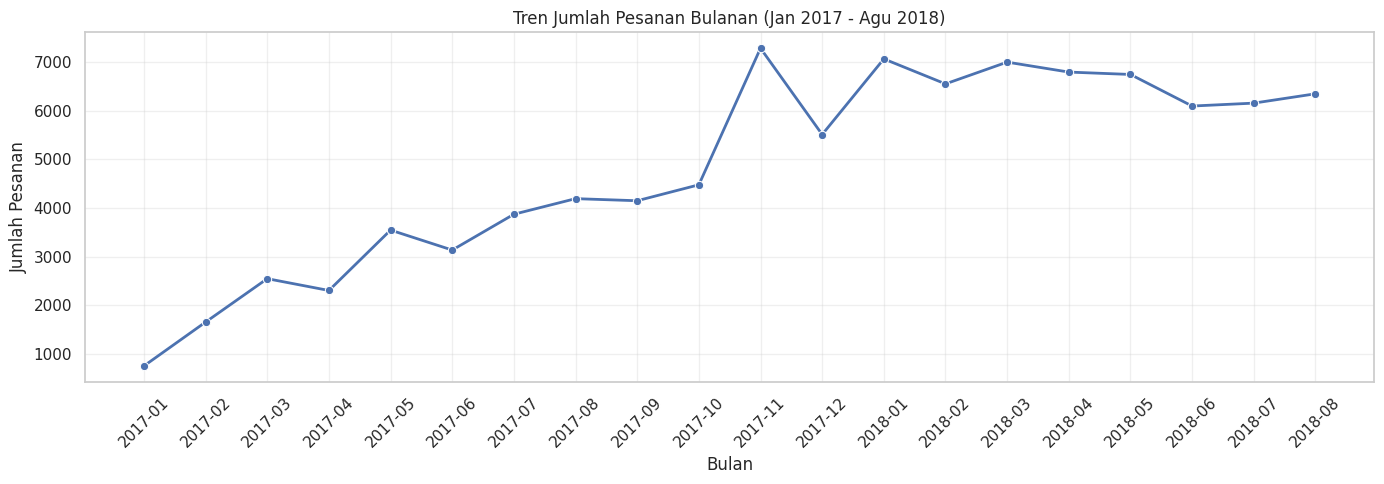

In [58]:

# Visualisasi tren jumlah pesanan bulanan
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x='month',
    y='total_orders',
    marker='o',
    linewidth=2
)

plt.title('Tren Jumlah Pesanan Bulanan (Jan 2017 - Agu 2018)')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Pesanan')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


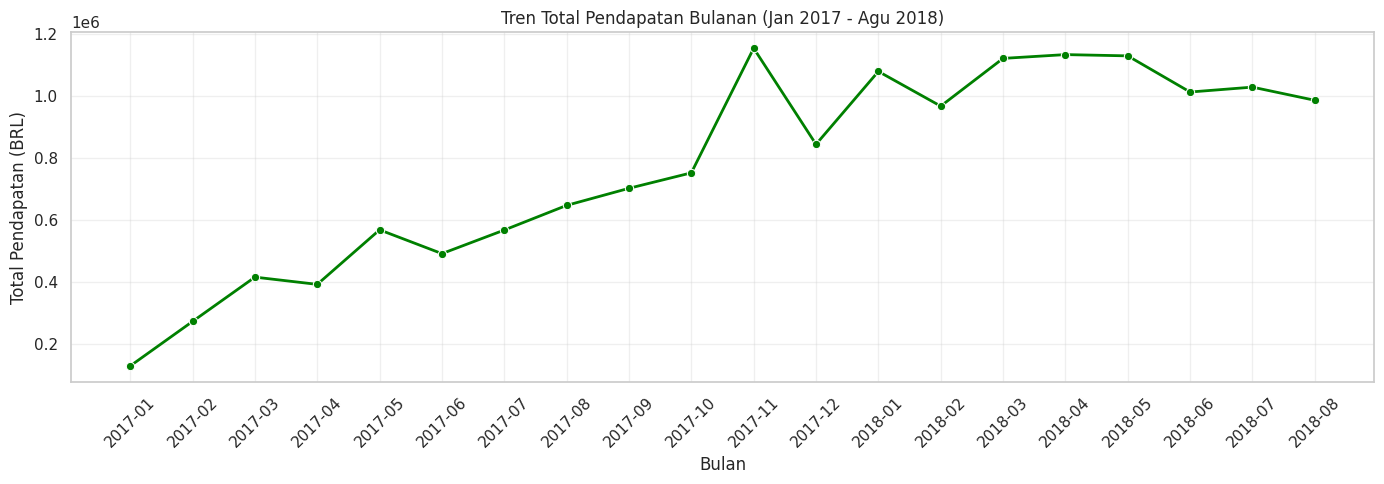

In [59]:

# Visualisasi tren pendapatan bulanan
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x='month',
    y='total_revenue',
    marker='o',
    linewidth=2,
    color='green'
)

plt.title('Tren Total Pendapatan Bulanan (Jan 2017 - Agu 2018)')
plt.xlabel('Bulan')
plt.ylabel('Total Pendapatan (BRL)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


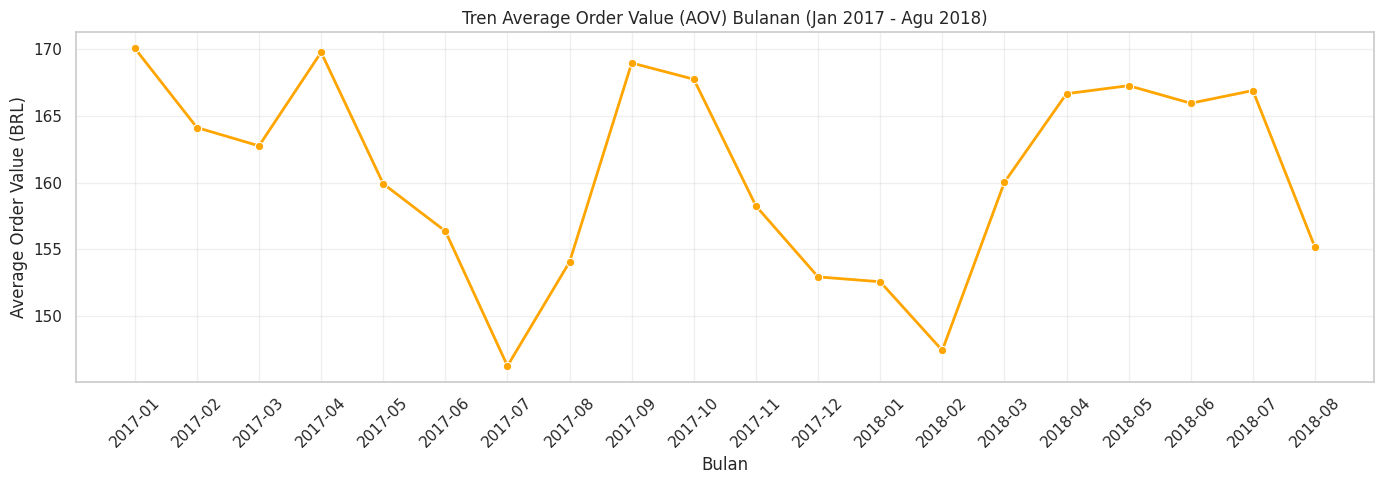

In [60]:

# Visualisasi tren AOV bulanan
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x='month',
    y='AOV',
    marker='o',
    linewidth=2,
    color='orange'
)

plt.title('Tren Average Order Value (AOV) Bulanan (Jan 2017 - Agu 2018)')
plt.xlabel('Bulan')
plt.ylabel('Average Order Value (BRL)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


**Kesimpulan Analisis Tren Pesanan dan Pendapatan**

Berdasarkan analisis periode Januari 2017 hingga Agustus 2018, jumlah pesanan dan pendapatan meningkat hingga mencapai puncak pada November 2017, yaitu 7.289 pesanan dengan total pendapatan R$1.153.528,05. Setelah periode tersebut, performa tidak terus meningkat secara konsisten. Pada Juni–Agustus 2018, jumlah pesanan bergerak dari 6.099 menjadi 6.351 pesanan, sedangkan pendapatan turun dari R$1.012.090,68 pada Juni menjadi R$985.414,28 pada Agustus. Dengan demikian, pemulihan jumlah pesanan pada Agustus belum diikuti pemulihan pendapatan.

AOV juga berfluktuasi sepanjang periode analisis dan tidak menunjukkan tren kenaikan yang konsisten. Nilai AOV tertinggi terjadi pada Januari 2017 sebesar R$170,06, sedangkan pada Agustus 2018 AOV berada pada R$155,16. Hal ini menunjukkan bahwa perubahan pendapatan dipengaruhi oleh kombinasi jumlah pesanan dan nilai rata-rata transaksi, bukan hanya pertumbuhan jumlah pesanan.

**Tindak lanjut bisnis:** evaluasi faktor yang mendorong puncak penjualan pada November 2017 untuk direplikasi pada periode yang relevan; kemudian telusuri penyebab penurunan pendapatan pada Juni–Agustus 2018 berdasarkan kategori produk, promosi, dan nilai transaksi. Strategi peningkatan penjualan sebaiknya tidak hanya mengejar jumlah pesanan, tetapi juga menjaga AOV melalui bundling atau rekomendasi produk yang relevan.

### **Pertanyaan 2:** Customer RFM: Bagaimana karakteristik pelanggan berdasarkan Recency, Frequency, Monetary, dan distribusi segmen RFM dari riwayat transaksi selama periode 1 Januari 2017 hingga 31 Agustus 2018, dengan tanggal analisis 1 September 2018, sebagai dasar penentuan strategi retensi pelanggan dan program pembelian ulang?


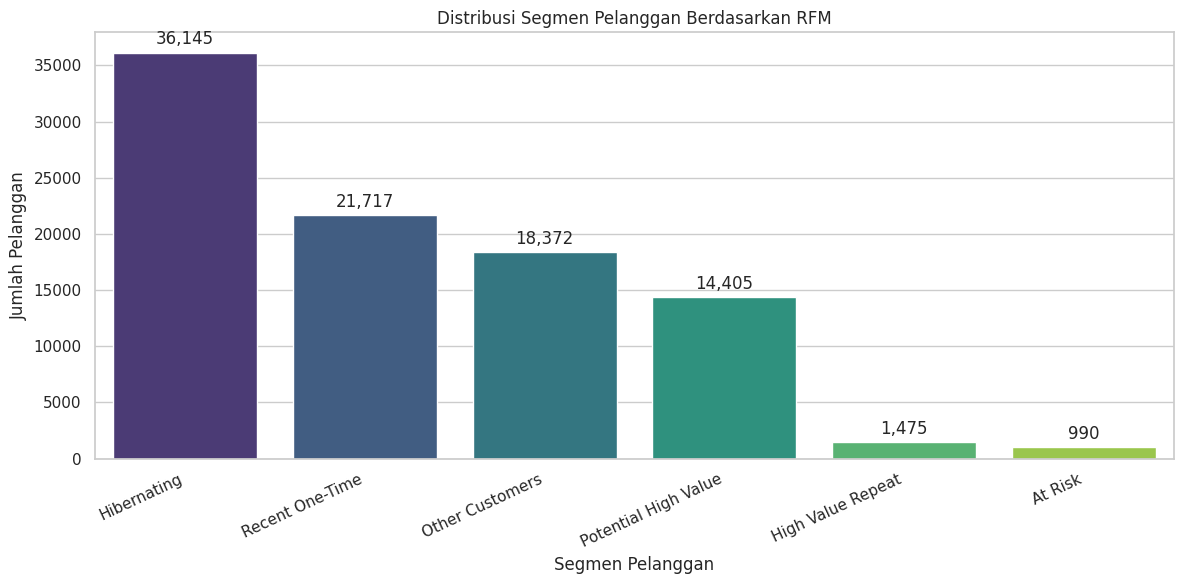

In [61]:

# Menghitung jumlah pelanggan setiap segmen
segment_counts = (
    rfm_scored['Segment']
    .value_counts()
    .sort_values(ascending=False)
)

# Membuat visualisasi distribusi segmen pelanggan
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values,
    hue=segment_counts.index,
    palette='viridis',
    legend=False
)

# Menambahkan label jumlah pelanggan
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

plt.title('Distribusi Segmen Pelanggan Berdasarkan RFM')
plt.xlabel('Segmen Pelanggan')
plt.ylabel('Jumlah Pelanggan')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()

plt.show()


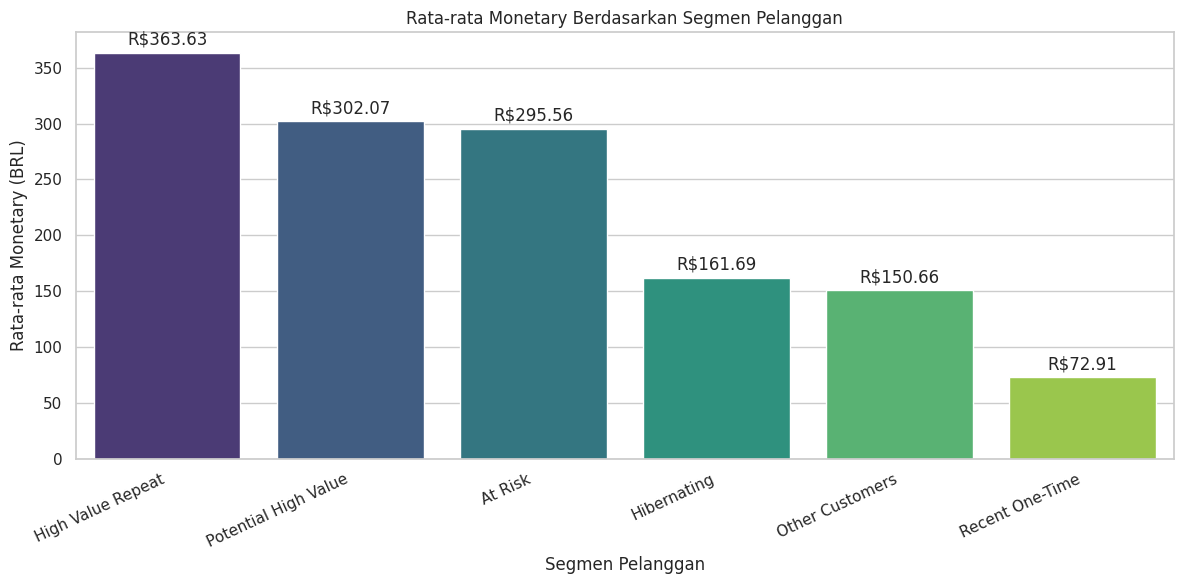

In [62]:

# Menghitung rata-rata Monetary setiap segmen
segment_monetary = (
    rfm_scored.groupby('Segment')['Monetary']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Visualisasi rata-rata Monetary
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_monetary,
    x='Segment',
    y='Monetary',
    hue='Segment',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='R$%.2f', padding=3)

plt.title('Rata-rata Monetary Berdasarkan Segmen Pelanggan')
plt.xlabel('Segmen Pelanggan')
plt.ylabel('Rata-rata Monetary (BRL)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()

plt.show()


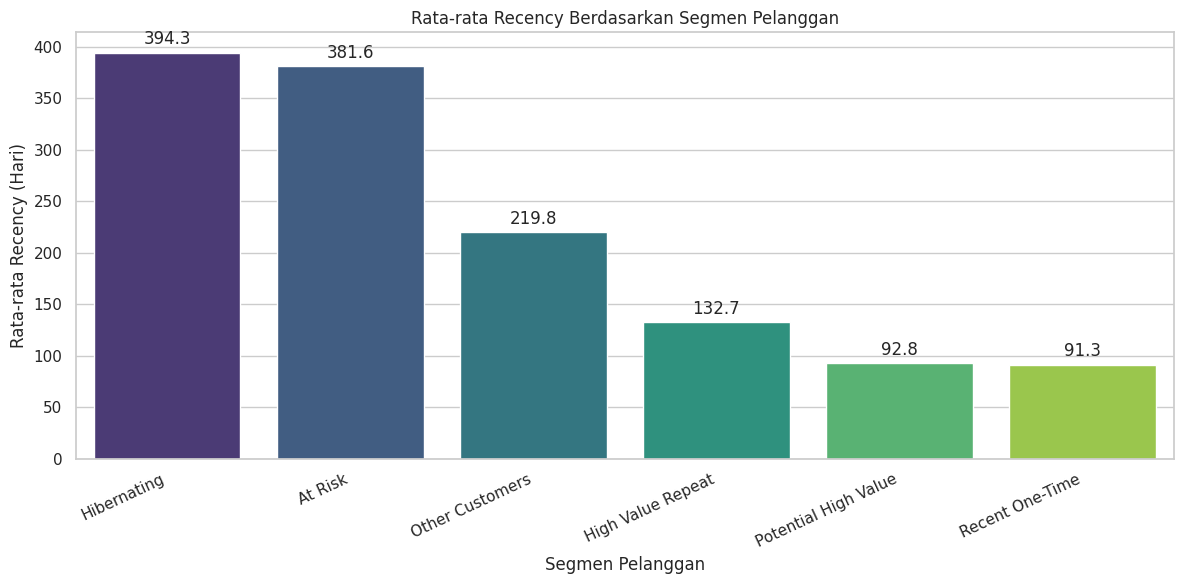

In [63]:

# Menghitung rata-rata Recency setiap segmen
segment_recency = (
    rfm_scored.groupby('Segment')['Recency']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Visualisasi rata-rata Recency
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_recency,
    x='Segment',
    y='Recency',
    hue='Segment',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.title('Rata-rata Recency Berdasarkan Segmen Pelanggan')
plt.xlabel('Segmen Pelanggan')
plt.ylabel('Rata-rata Recency (Hari)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()

plt.show()


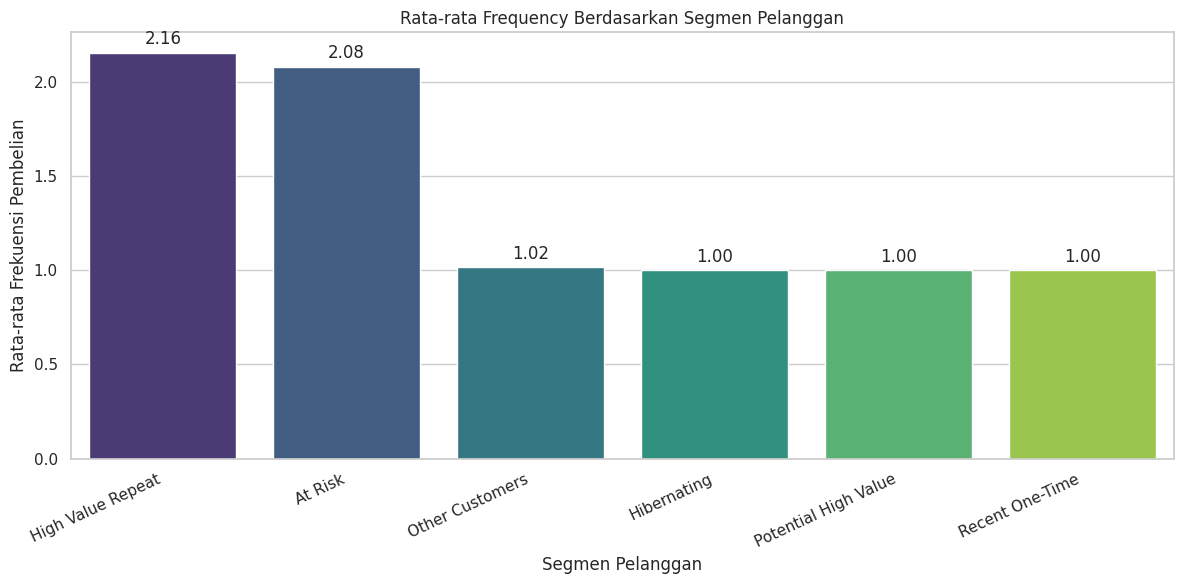

In [64]:

# Menghitung rata-rata Frequency setiap segmen
segment_frequency = (
    rfm_scored.groupby('Segment')['Frequency']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Visualisasi rata-rata Frequency
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_frequency,
    x='Segment',
    y='Frequency',
    hue='Segment',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.title('Rata-rata Frequency Berdasarkan Segmen Pelanggan')
plt.xlabel('Segmen Pelanggan')
plt.ylabel('Rata-rata Frekuensi Pembelian')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()

plt.show()


**Kesimpulan Analisis Karakteristik Pelanggan (RFM)**

Berdasarkan analisis RFM terhadap 93.104 pelanggan, mayoritas pelanggan masih memiliki frekuensi pembelian yang rendah, yaitu sekitar 97% pelanggan hanya melakukan satu kali pembelian. Segmen Hibernating menjadi kelompok terbesar dengan 36.145 pelanggan (38,82%), sedangkan High Value Repeat hanya mencakup 1.475 pelanggan (1,58%). Di sisi lain, Potential High Value memiliki rata-rata Monetary sebesar R$302,07 dan Recency 92,8 hari, sehingga menjadi kelompok potensial untuk didorong melakukan pembelian ulang. Oleh karena itu, bisnis perlu menerapkan strategi reaktivasi bagi pelanggan yang sudah lama tidak bertransaksi, memberikan penawaran khusus kepada pelanggan potensial, serta mempertahankan pelanggan yang sudah melakukan pembelian berulang.

### Pertanyaan 3: Bagaimana persentase pesanan yang terkirim tepat waktu dan terlambat, serta rata-rata durasi pengiriman selama Januari 2017 hingga Agustus 2018, sebagai dasar evaluasi kinerja logistik dan penentuan prioritas perbaikan pengiriman?

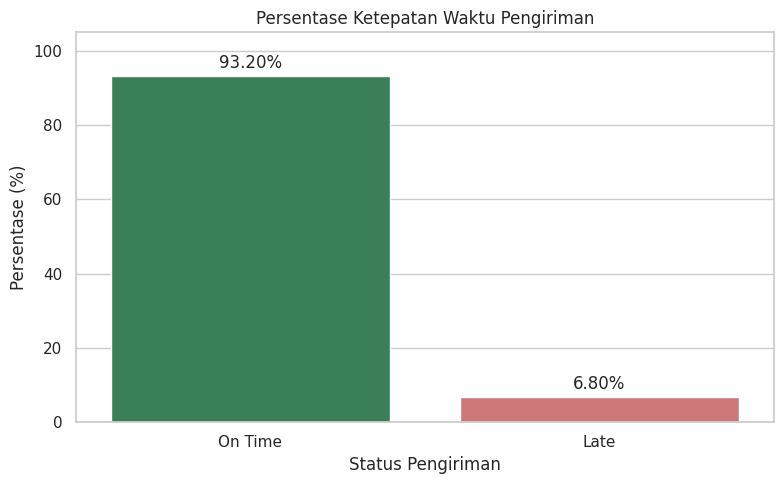

In [65]:

# Menghitung persentase ketepatan pengiriman
delivery_percentage = (
    delivery_data['delivery_status']
    .value_counts(normalize=True)
    .reindex(['On Time', 'Late']) * 100
)

# Membuat visualisasi
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=delivery_percentage.index,
    y=delivery_percentage.values,
    hue=delivery_percentage.index,
    palette=['#2E8B57', '#DC6B6B'],
    legend=False
)

# Menampilkan label persentase
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title('Persentase Ketepatan Waktu Pengiriman')
plt.xlabel('Status Pengiriman')
plt.ylabel('Persentase (%)')
plt.ylim(0, 105)
plt.tight_layout()

plt.show()


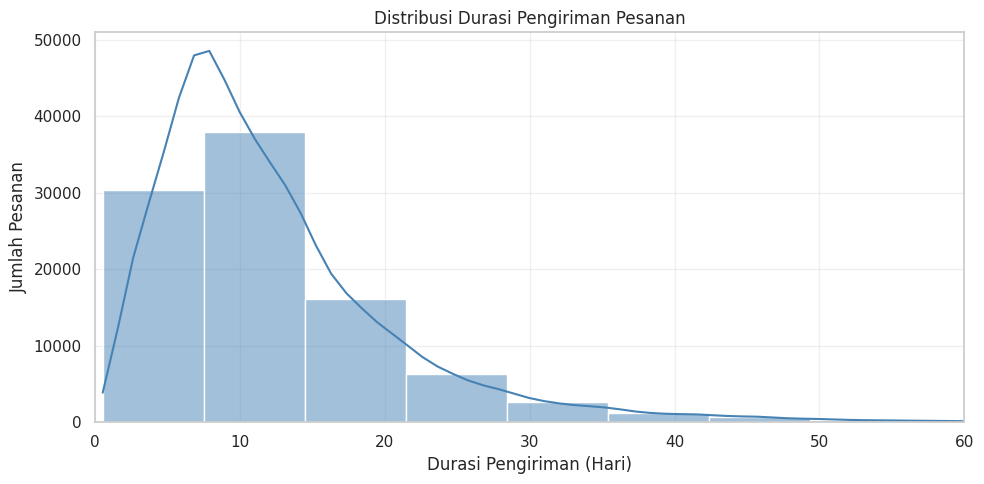

In [66]:

# Visualisasi distribusi durasi pengiriman
plt.figure(figsize=(10, 5))

sns.histplot(
    data=delivery_data,
    x='delivery_duration',
    bins=30,
    kde=True,
    color='steelblue'
)

plt.title('Distribusi Durasi Pengiriman Pesanan')
plt.xlabel('Durasi Pengiriman (Hari)')
plt.ylabel('Jumlah Pesanan')
plt.xlim(0, 60)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


**Kesimpulan Analisis Performa Pengiriman**

Setelah mengeluarkan pesanan dengan timestamp tidak konsisten dan baris dengan tanggal analisis yang dibutuhkan kosong, analisis mencakup 96.019 pesanan delivered pada periode Januari 2017 hingga Agustus 2018. Sebanyak 89.490 pesanan (93,20%) diterima tepat waktu, sedangkan 6.529 pesanan (6,80%) terlambat. Rata-rata durasi pengiriman dari pembelian hingga diterima pelanggan adalah 12,55 hari, dengan median 10,22 hari. Pada pesanan yang terlambat, rata-rata keterlambatan mencapai 10,62 hari.

Hasil ini menunjukkan bahwa mayoritas pesanan diterima tepat waktu, tetapi keterlambatan masih terjadi pada sebagian pesanan. **Tindak lanjut bisnis:** evaluasi jalur pengiriman dan seller/area dengan proporsi keterlambatan tinggi, lalu prioritaskan perbaikan pada area yang paling sering terlambat. Hasil perlu dibaca dengan mempertimbangkan bahwa pesanan yang memiliki timestamp tidak konsisten atau tanggal penting yang kosong tidak disertakan dalam perhitungan performa pengiriman.

**Insight:** (Opsional)
1. Pertanyaan 1: Tren pesanan dan pendapatan meningkat dibandingkan awal periode, dengan puncak pada November 2017.
2. Pertanyaan 2: Mayoritas pelanggan hanya melakukan satu kali pembelian, sehingga peluang peningkatan pembelian ulang masih besar.
3. Pertanyaan 3: Pengiriman sebagian besar tepat waktu (93,21%), tetapi keterlambatan pada sebagian pesanan masih perlu dievaluasi.

## Conclusion & Recommendation

1.Tren Pesanan dan Pendapatan

Berdasarkan analisis periode Januari 2017 hingga Agustus 2018, jumlah pesanan dan pendapatan mengalami fluktuasi setiap bulannya. Puncak transaksi terjadi pada November 2017 dengan 7.289 pesanan dan total pendapatan sebesar R$1.153.528,05. Secara keseluruhan, total pendapatan mencapai R$15.375.875,44 dengan rata-rata nilai transaksi (AOV) sebesar R$159,81. Hasil ini menunjukkan adanya periode dengan aktivitas penjualan yang tinggi, sehingga pola transaksi bulanan dapat dimanfaatkan sebagai dasar dalam menentukan strategi promosi.

2.Karakteristik Pelanggan (RFM)

Analisis RFM terhadap 93.104 pelanggan menunjukkan bahwa sekitar 97% pelanggan hanya melakukan satu kali pembelian. Segmen Hibernating menjadi kelompok terbesar dengan 38,82%, sedangkan segmen High Value Repeat hanya sebesar 1,58%. Selain itu, segmen Potential High Value memiliki rata-rata nilai transaksi sebesar R$302,07. Kondisi ini menunjukkan bahwa perusahaan memiliki peluang untuk meningkatkan pembelian ulang, mengaktifkan kembali pelanggan yang tidak aktif, serta mempertahankan pelanggan bernilai tinggi.

3.Performa Pengiriman

Dari 96.019 pesanan yang dianalisis selama Januari 2017 hingga Agustus 2018, sebanyak 89.490 pesanan (93,20%) berhasil diterima tepat waktu, sedangkan 6.529 pesanan (6,80%) mengalami keterlambatan. Rata-rata durasi pengiriman mencapai 12,55 hari dengan median 10,22 hari. Sementara itu, rata-rata keterlambatan pada pesanan yang terlambat mencapai 10,62 hari. Hasil ini menunjukkan bahwa sebagian besar pesanan berhasil dikirim tepat waktu, tetapi keterlambatan pada sebagian pesanan masih perlu dievaluasi untuk meningkatkan kualitas layanan logistik.

** Recommendation **

1. **Penjualan:** Mengevaluasi pola penjualan bulanan dan merencanakan promosi pada periode dengan potensi transaksi tinggi, serta memantau perubahan jumlah pesanan dan pendapatan setelah promosi dilakukan.

2. **Retensi Pelanggan:** Memberikan voucher pembelian kedua kepada pelanggan yang baru melakukan satu kali transaksi untuk mendorong pembelian ulang.

3. **Pelanggan Tidak Aktif dan Potensial:** Menjalankan kampanye reaktivasi melalui penawaran khusus kepada segmen Hibernating serta mengembangkan program loyalitas dan penawaran personal bagi segmen Potential High Value.

4. **Pengiriman:** Mengevaluasi pesanan yang mengalami keterlambatan, mengidentifikasi penyebab keterlambatan, serta meningkatkan koordinasi dan pemantauan kinerja mitra logistik agar durasi pengiriman dapat lebih terkendali.

In [67]:

# Menyimpan hasil analisis ke CSV

monthly_sales.to_csv(
    '/content/monthly_sales.csv',
    index=False
)

rfm_scored.to_csv(
    '/content/rfm_scored.csv',
    index=False
)

delivery_data.to_csv(
    '/content/delivery_data.csv',
    index=False
)

print("File hasil analisis berhasil disimpan!")


File hasil analisis berhasil disimpan!


In [68]:

import os

files = [
    'monthly_sales.csv',
    'rfm_scored.csv',
    'delivery_data.csv'
]

for file in files:
    path = f'/content/{file}'
    print(file, ":", os.path.getsize(path), "bytes")


monthly_sales.csv : 876 bytes
rfm_scored.csv : 6564008 bytes
delivery_data.csv : 13777018 bytes
